In [110]:
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

file = open("pantadeusz.txt", "r")
len(file.read())

441702

In [126]:
def sort(lst):
    return list(reversed(sorted(lst.items(), key=lambda kv: kv[1])))

import re

class BookWord(str):
  def trim(self):
     return re.sub(r"^\W+|\W+$", "", self)

  def strip(self):
     return re.replace(r"\s", "", self)

print('test', BookWord('A asd asd ').trim().strip().lower(),)


# print(list(map(lambda e: e.trim(), map(lambda f: BookWord(f), ('abc', 'cde.', 'fgh,')))))

def normalize_words(words):
   return list(map(lambda e: e.trim().lower().strip(), map(lambda f: BookWord(f), words)))


test a asd asd


In [114]:
def ex01_imp(text: str, how_many: int = 10, word_len: int = None) -> dict[str, int]:
  most_frequent = defaultdict(int)
  longest = defaultdict(int)
  split = normalize_words(text.split())
  unique_words = set(split)

  for word in split:
    if not word_len is None:
      if len(word) > word_len:
        most_frequent[word] += 1
    else:
      most_frequent[word] += 1

  for word in unique_words:
    longest[word] = len(word)

  sorted_most_frequent = sort(most_frequent)
  sorted_longest = sort(longest)

  return sorted_most_frequent[:how_many], sorted_longest[:how_many]


file.seek(0)
text = file.read()
most_frequent, longest = ex01_imp(text)
print("Most frequent words", most_frequent)
print("Longest words", longest)
# most_frequent, _ = ex01_imp(text, 10, 3)
# print("Most frequent words longer than 3", most_frequent)



Most frequent words [('i', 2114), ('w', 1684), ('się', 1486), ('z', 1370), ('na', 1295), ('nie', 938), ('', 610), ('jak', 578), ('a', 565), ('do', 564)]
Longest words [('karol-kochanku-radziwiłł', 24), ('podkomorzy-marszałek', 20), ('białopiotrowiczowi', 18), ('niebezpieczeństwem', 18), ('najprzykładniejszy', 18), ('białopiotrowiczem', 17), ('rycersko-feudalny', 17), ('nierozstrzygniony', 17), ('radziwiłł-sierota', 17), ('niebezpieczeństwo', 17)]


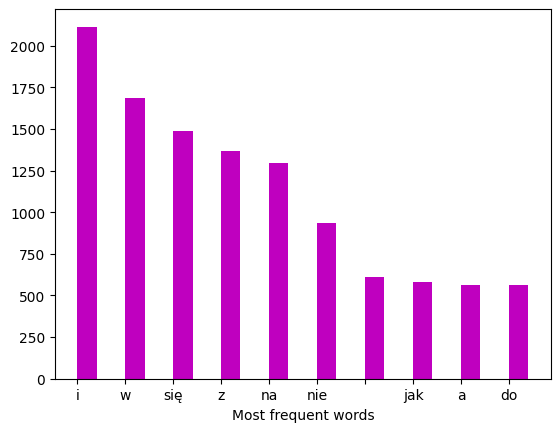

In [115]:

get_by_index = lambda collection, index: list(map(lambda e: e[index], collection))

words = get_by_index(most_frequent, 0)
counts = get_by_index(most_frequent, 1)
plt.bar(words, counts, color= 'm', width = 0.4 , align = 'edge')
plt.xlabel("Most frequent words")

plt.show()

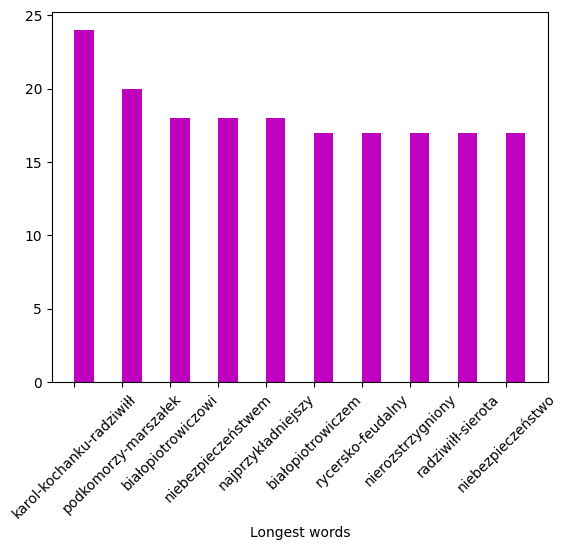

In [ ]:
words = get_by_index(longest, 0)
counts = get_by_index(longest, 1)
plt.bar(words, counts, color= 'm', width = 0.4 , align = 'edge')
plt.xlabel("Longest words",)
plt.xticks(rotation=45)

plt.show()

In [ ]:
from functools import reduce


def ex01_fun(text: str, how_many: int = 10, word_len: int = None) -> dict[str, int]:
  split = normalize_words(text.split())
  most_frequent = sort(
      reduce(
        lambda acc, w: acc.update({w: acc.get(w, 0) + 1}) or acc, split, {}))
  longest = sort(
      reduce(
        lambda acc, w: acc.update({ w: len(w) }) or acc, set(split), {})
  )
  return most_frequent[:how_many], longest[:how_many]

file.seek(0)
text = file.read()

most_frequent, longest = ex01_fun(text)
print("Most frequent words", most_frequent)
print("Longest words", longest)



Most frequent words [('i', 2114), ('w', 1684), ('się', 1486), ('z', 1370), ('na', 1295), ('nie', 938), ('', 610), ('jak', 578), ('a', 565), ('do', 564)]
Longest words [('karol-kochanku-radziwiłł', 24), ('podkomorzy-marszałek', 20), ('białopiotrowiczowi', 18), ('niebezpieczeństwem', 18), ('najprzykładniejszy', 18), ('białopiotrowiczem', 17), ('rycersko-feudalny', 17), ('nierozstrzygniony', 17), ('radziwiłł-sierota', 17), ('niebezpieczeństwo', 17)]


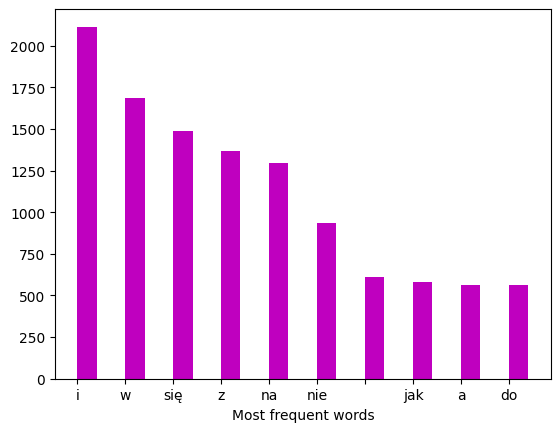

In [ ]:
words = get_by_index(most_frequent, 0)
counts = get_by_index(most_frequent, 1)
plt.bar(words, counts, color= 'm', width = 0.4 , align = 'edge')
plt.xlabel("Most frequent words")

plt.show()

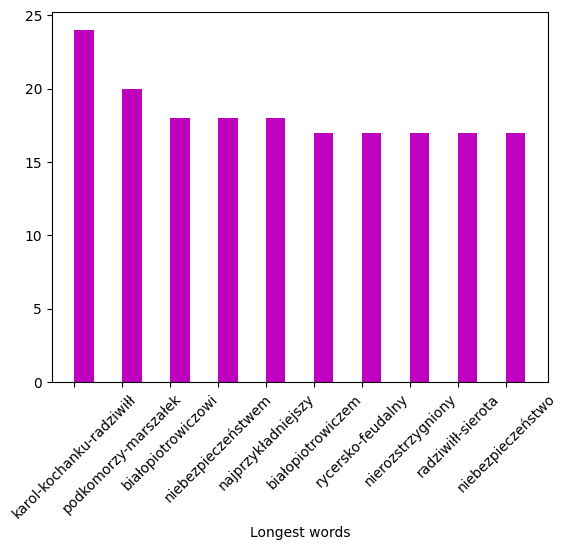

In [ ]:
words = get_by_index(longest, 0)
counts = get_by_index(longest, 1)
plt.bar(words, counts, color= 'm', width = 0.4 , align = 'edge')
plt.xlabel("Longest words",)
plt.xticks(rotation=45)

plt.show()